# Convert to Dataframe Using Multiprocessing Pool

Authors: TDM Studio Team and Naomi Baes

#### Background Context
**Multiprocessing** is a useful python package that enables users to utilize multiple processors on a given machine for more efficient progress. The Pool object allows the exploitation of data parallelism by distributing the work across a pool of processes running the same function. This greatly improves the speed at which the work is done, reducing overall runtime.

Multiprocessing is mainly preferred when calling functions on larger sets of data expressing data parallelism. Data parallelism is the concept of breaking a set of data into smaller sets, which is then processed on multiple processes applying the same function without communicating with each other. Joining the output of these processes should produce the same result as if one process had applied the function to the entire dataset.

#### Script Purpose
This script is the multiprocessing variation of the **Convert to Dataframe** script. In this sample script, we will demonstrate the use of Multiprocessing Pool in parsing large numbers of XML files. We will create the function for parsing, create a pool object, and then call the function using that pool object to run via multiprocessing.

#### Expected Runtime and Sample Size
Mileage will vary depending on document size and resources available. On the standard notebook instance with 4 cores, expect around 8 minutes of runtime to process 53k New York Times articles and around 2 minutes of runtime to process 5k dissertations. The beginning input size is set to the corpus `SAMPLEDATA`, which includes around 53k articles.

## Import Libraries

In [79]:
# Libraries for parsing data
from lxml import etree
from bs4 import BeautifulSoup
import pandas as pd
import os

# Libraries for multiprocessing
import multiprocessing as mp
from multiprocessing import Pool

In [80]:
#! pip install bs4
#!pip install lxml

## Load Data

In [81]:
# Set corpus to the folder of files you want to use
corpus = '/home/ec2-user/SageMaker/data/ADHD_US_newsstream/'

# Read in files
input_files = os.listdir(corpus)

print("Loaded", len(input_files), "documents.")

Loaded 107193 documents.


## Specify Output File

Define the `output_file` variable to the desired save location and file name. This variable will be used at the end of the script to save the processed data.

In [82]:
# Modify output_file to desired save name
output_file = 'output/ADHD_US_newsstream.csv'

In [83]:
pwd

'/home/ec2-user/SageMaker/ADHD_conceptual_change/0_corpus_processing'

In [84]:
# Define the folder name
output_folder = "output"

# Create the folder if it doesn't exist
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Created folder: '{output_folder}'")
else:    
    print(f"Folder already exists: '{output_folder}'")

Folder already exists: 'output'


In [85]:
# Define the folder name
output_folder = "output/descriptives"

# Create the folder if it doesn't exist
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Created folder: '{output_folder}'")
else:    
    print(f"Folder already exists: '{output_folder}'")

Folder already exists: 'output/descriptives'


## Check Total Cores

Check the total number of cores on your current device. The following multiprocessing portions will be using this variable.

In [86]:
# Check core count
num_cores = mp.cpu_count()
print(num_cores)

8


## Define Functions

In [87]:
# Function to strip html tags from text portion
def strip_html_tags(text):
    stripped = BeautifulSoup(text).get_text().replace('\n', ' ').replace('\\', '').strip()
    return stripped

In [88]:
# Retrieve metadata from XML document
def getxmlcontent(corpus, file, strip_html=True):
    try:
        tree = etree.parse(corpus + file)
        root = tree.getroot()

        if root.find('.//GOID') is not None:
            goid = root.find('.//GOID').text
        else:
            goid = None

        if root.find('.//Title') is not None:
            title = root.find('.//Title').text
        else:
            title = None

        if root.find('.//NumericDate') is not None:
            date = root.find('.//NumericDate').text
        else:
            date = None
            
        if root.find('.//PublisherName') is not None:
            publisher = root.find('.//PublisherName').text
        else:
            publisher = None

        if root.find('.//FullText') is not None:
            text = root.find('.//FullText').text

        elif root.find('.//HiddenText') is not None:
            text = root.find('.//HiddenText').text

        elif root.find('.//Text') is not None:
            text = root.find('.//Text').text

        else:
            text = None

        # Strip html from text portion
        if text is not None and strip_html == True:
            text = strip_html_tags(text)
            
        if root.find('.//PubFrosting/SourceType') is not None:
            sourcetype = root.find('.//PubFrosting/SourceType').text
        else:
            sourcetype = None
        
        if root.find('.//PubFrosting/publisher/PublisherAddress/Province') is not None:
            pubprovince = root.find('.//PubFrosting/publisher/PublisherAddress/Province').text
        else:
            pubprovince = None
    
    except Exception as e:
        print(f"Error while parsing file {file}: {e}")
    
    return goid, title, date, publisher, text, sourcetype, pubprovince

In [89]:
# Function to make lists out of parsed data--on single document scale for multiprocessing
def make_lists(file):
    
    goid, title, date, publisher, text, sourcetype, pubprovince = getxmlcontent(corpus, file, strip_html=True)
    
    return goid, title, text, date, publisher, sourcetype, pubprovince

## Run Multiprocessing to parse XML files

In [90]:
# Test function on single document
make_lists(input_files[1])

('325512480',
 "LIBRARIANS: CHECK THESE OUT AMERICAN LIBRARY ASSOCIATION RECENTLY ANNOUNCED WINNERS OF THE CALDECOTT AND NEWBERY MEDALS HONORING CHILDREN'S LITERATURE",
 None,
 '2001-02-02',
 'Syracuse Newspapers, Inc.',
 'Newspapers',
 'NY')

In [91]:
# When using multiple processes, important to eventually close them to avoid memory/resource leaks
try:
    # Define a thread Pool to process multiple XML files simultaneously
    # Default set to num_cores - 1, but may change number of processes depending on instance
    p = Pool(processes=num_cores-1)
    
    # Apply function with Pool to corpus
    processed_lists = p.map(make_lists, input_files)

except Exception as e:
    print(f"Error in processing document: {e}")
    
finally:
    p.close()

In [92]:
# Transform processed data into a dataframe
df = pd.DataFrame(processed_lists, columns=['GOID', 'Title', 'Text', 'Date', 'Publisher', 'SourceType', 'PublisherProvince'])

In [93]:
# View dataframe
df

,GOID,Title,Text,Date,Publisher,SourceType,PublisherProvince
0,1357126016,A Message for the Class of 2013; Dear Graduate...,"Thank you, President and Trustees. I have to c...",2013-05-31,Dow Jones & Company Inc.,"Blogs, Podcasts, & Websites",NJ
1,325512480,LIBRARIANS: CHECK THESE OUT AMERICAN LIBRARY A...,None,2001-02-02,"Syracuse Newspapers, Inc.",Newspapers,NY
2,865291198,Questionnaire: Rick Morelli,Full Name: Rick Morelli Date of Birth: 1-21-...,2011-05-09,The Citizens' Voice,Newspapers,PA
3,3031447880,How do we help our 4-year-old who always wants...,Dear Meghan: Do you have any advice for setti...,2024-04-04,WP Company LLC d/b/a The Washington Post,Newspapers,DC
4,2459482004,"To Boston parents, treatment of most vulnerabl...",Sign up to receive a newsletter for The Great ...,2020-11-12,"Boston Globe Media Partners, LLC",Newspapers,MA
...,...,...,...,...,...,...,...
107188,2535994751,State of the Nation's Mental Health: Stress is...,(BPT) - Our nation reported more mental health...,2021-06-01,The Citizens' Voice,Newspapers,PA
107189,2012573674,THE FRAGILE STAGE: Considering the wide range ...,March 10--Editor's Note: This is the first of ...,2018-03-10,Tribune Content Agency LLC,Wire Feeds,None
107190,749942706,"Pediatrician: What is causing self-injury, or ...",I am hearing my daughter's friends talking abo...,2010-09-08,Daily Herald,Newspapers,IL
107191,396287977,Former Houston Baptist teacher receives honor ...,None,2006-07-20,"Hearst Communications Inc., Hearst Newspapers ...",Newspapers,NY


In [94]:
# Ensure 'Date' column is in datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extract 4-digit year and create new column 'year'
df['year'] = df['Date'].dt.year

df.columns = ['id','title', 'text','date','publisher','source_type', 'pub_province','year']

# Preview the updated DataFrame
df.head()

,id,title,text,date,publisher,source_type,pub_province,year
0,1357126016,A Message for the Class of 2013; Dear Graduate...,"Thank you, President and Trustees. I have to c...",2013-05-31,Dow Jones & Company Inc.,"Blogs, Podcasts, & Websites",NJ,2013
1,325512480,LIBRARIANS: CHECK THESE OUT AMERICAN LIBRARY A...,None,2001-02-02,"Syracuse Newspapers, Inc.",Newspapers,NY,2001
2,865291198,Questionnaire: Rick Morelli,Full Name: Rick Morelli Date of Birth: 1-21-...,2011-05-09,The Citizens' Voice,Newspapers,PA,2011
3,3031447880,How do we help our 4-year-old who always wants...,Dear Meghan: Do you have any advice for setti...,2024-04-04,WP Company LLC d/b/a The Washington Post,Newspapers,DC,2024
4,2459482004,"To Boston parents, treatment of most vulnerabl...",Sign up to receive a newsletter for The Great ...,2020-11-12,"Boston Globe Media Partners, LLC",Newspapers,MA,2020


## Inspect CSV

NAs

In [95]:
df.isna().sum()

id                  0
title               0
text            22689
date                0
publisher           0
source_type         0
pub_province     9542
year                0
dtype: int64

In [96]:
len(df) # get total # of rows before dropping NA rows

107193

In [97]:
df = df.dropna(subset=['text']) # drop rows where 'Text' column is missing Nan

In [98]:
len(df) # get total # of rows after dropping NA rows

84504

In [99]:
df.isna().sum()

id                 0
title              0
text               0
date               0
publisher          0
source_type        0
pub_province    8488
year               0
dtype: int64

In [100]:
# Check that all article ids are unique
df['id'].is_unique

True

## Descriptive Statistics

In [101]:
desc_output_folder = 'output/descriptives'

### Text counts

In [102]:
# count total entries per year (before removing missing 'text' entries)
row_counts_byyear = df.groupby('year').size().reset_index(name='count')

print(row_counts_byyear)

# save to csv
output_path = os.path.join(desc_output_folder, 'row_counts_byyear.csv')
row_counts_byyear.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

    year  count
0   1980      1
1   1983      2
2   1985      7
3   1986      5
4   1987     34
5   1988     43
6   1989     50
7   1990     99
8   1991    134
9   1992    237
10  1993    355
11  1994    651
12  1995    696
13  1996    990
14  1997   1061
15  1998   1232
16  1999   1707
17  2000   2113
18  2001   1804
19  2002   2091
20  2003   2344
21  2004   2569
22  2005   3082
23  2006   3305
24  2007   3755
25  2008   3366
26  2009   3286
27  2010   3174
28  2011   3185
29  2012   3282
30  2013   3709
31  2014   3818
32  2015   3427
33  2016   3015
34  2017   3052
35  2018   3030
36  2019   3219
37  2020   2336
38  2021   2534
39  2022   2835
40  2023   3860
41  2024   3373
42  2025   1636
Saved to output/descriptives/row_counts_byyear.csv


In [103]:
# count non-missing 'text' entries per year
text_counts_byyear = df.groupby('year')['text'].count().reset_index(name='count')

print(text_counts_byyear)

# save to csv
output_path = os.path.join(desc_output_folder, 'text_counts_byyear.csv')
text_counts_byyear.to_csv(output_path, index=False)

print(f"Saved tp {output_path}")

    year  count
0   1980      1
1   1983      2
2   1985      7
3   1986      5
4   1987     34
5   1988     43
6   1989     50
7   1990     99
8   1991    134
9   1992    237
10  1993    355
11  1994    651
12  1995    696
13  1996    990
14  1997   1061
15  1998   1232
16  1999   1707
17  2000   2113
18  2001   1804
19  2002   2091
20  2003   2344
21  2004   2569
22  2005   3082
23  2006   3305
24  2007   3755
25  2008   3366
26  2009   3286
27  2010   3174
28  2011   3185
29  2012   3282
30  2013   3709
31  2014   3818
32  2015   3427
33  2016   3015
34  2017   3052
35  2018   3030
36  2019   3219
37  2020   2336
38  2021   2534
39  2022   2835
40  2023   3860
41  2024   3373
42  2025   1636
Saved tp output/descriptives/text_counts_byyear.csv


## Publication type counts

In [104]:
# --------- Per-year summary ---------
source_type_stats_by_year = df.groupby('year')['source_type'].agg(
    unique_count='nunique',
    source_Type_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'source_type_counts_byyear.csv')
source_type_stats_by_year.to_csv(yearly_output_path, index=False)

print(f"Saved per-year province summary to {yearly_output_path}")


Saved per-year province summary to output/descriptives/source_type_counts_byyear.csv


In [105]:
# --------- Overall total summary for source_type ---------
source_type_counts = df['source_type'].dropna().value_counts().sort_index()

# Save summary with counts
total_output_path = os.path.join(desc_output_folder, 'source_type_total_summary.txt')

with open(total_output_path, 'w') as f:
    f.write(f"Total unique source types: {len(source_type_counts)}\n\n")
    f.write("Source type counts:\n")
    for source_type, count in source_type_counts.items():
        f.write(f"{source_type}: {count}\n")

print(f"Saved overall source_type summary to {total_output_path}")

Saved overall source_type summary to output/descriptives/source_type_total_summary.txt


## Province counts

In [106]:
# --------- Per-year summary ---------
province_stats_by_year = df.groupby('year')['pub_province'].agg(
    unique_count='nunique',
    province_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'province_counts_byyear.csv')
province_stats_by_year.to_csv(yearly_output_path, index=False)

#print(province_stats_by_year)
print(f"Saved per-year province summary to {yearly_output_path}")


Saved per-year province summary to output/descriptives/province_counts_byyear.csv


In [107]:
# --------- Overall total summary ---------
all_provinces = df['pub_province'].dropna().unique()
all_provinces_sorted = sorted(all_provinces)
total_unique_provinces = len(all_provinces_sorted)

# Save total summary to separate file
total_output_path = os.path.join(desc_output_folder, 'province_total_summary.txt')
with open(total_output_path, 'w') as f:
    f.write(f"Total unique provinces: {total_unique_provinces}\n")
    f.write("Province list:\n")
    f.write(", ".join(all_provinces_sorted))

print(all_provinces_sorted)
print(f"Saved overall province summary to {total_output_path}")

['AK', 'BC', 'CA', 'CO', 'CT', 'California', 'DC', 'FL', 'GA', 'HI', 'Hawaii', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'Minnesota', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'New York', 'OH', 'OR', 'PA', 'Pennsylvania', 'SC', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY']
Saved overall province summary to output/descriptives/province_total_summary.txt


### publisher count

In [108]:
# --------- Per-year summary ---------
publisher_stats_by_year = df.groupby('year')['publisher'].agg(
    unique_count='nunique',
    province_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'publisher_counts_byyear.csv')
publisher_stats_by_year.to_csv(yearly_output_path, index=False)

#print(province_stats_by_year)
print(f"Saved per-year publisher summary to {yearly_output_path}")

Saved per-year publisher summary to output/descriptives/publisher_counts_byyear.csv


In [109]:
# --------- Overall total summary ---------
all_publisher = df['publisher'].dropna().unique()
all_publisher_sorted = sorted(all_publisher)
total_unique_publisher = len(all_publisher_sorted)

# Save total summary to separate file
total_output_path = os.path.join(desc_output_folder, 'publisher_total_summary.txt')
with open(total_output_path, 'w') as f:
    f.write(f"Total unique publisher: {total_unique_publisher}\n")
    f.write("Publisher list:\n")
    f.write(", ".join(all_publisher_sorted))

print(all_publisher_sorted)

print(f"Saved overall publisher summary to {total_output_path}")

['AOL Inc.', 'Acción Latina', 'Afro - American Company of Baltimore City', 'Alameda Publishing Corp.', 'Albuquerque Publishing Company', 'Amelimedia Communications, LLC', 'American City Business Journals', 'Apollo Global Managment', 'Atlanta Journal Constitution, LLC', 'Baltimore Sun', 'Bangor Daily News', 'Bay Area News Group', 'Bay State Banner', 'Beacon Media Inc.', 'Big Sky Publishing LLC', 'Billings Gazette', 'Bismarck Tribune', 'BizWest Media LLC', 'Black Press Group Ltd.', 'Boston Globe Media Partners, LLC', 'Boutin-McQuiston, Inc.', 'BridgeTower Media Holding Company', 'Buck County Courier Times', 'Business Publications Inc.', 'Business Publications Incorporated', 'Business Wire', 'Business-North Carolina', 'BusinessWest', 'CALmatters', 'CBJ, L. P.', 'CNN Newsource Sales, Inc.', 'Call and Post', 'Central New York Business Journal', 'Charleston Newspapers', 'Chattanooga Times Free Press', 'Clarity Media Group, Inc.', 'Columbia Broadcasting System', 'Columbia Daily Tribune', 'Col

In [110]:
# Count of unique publisher
publisher_counts = df['publisher'].value_counts(dropna=True)

# Print each publisher with its count
#print(publisher_counts)

# Temporarily disable row truncation in pandas
with pd.option_context('display.max_rows', None):
    print(publisher_counts)
    
# Save to a file
counts_output_path = os.path.join(desc_output_folder, 'publisher_counts.txt')
with open(counts_output_path, 'w') as f:
    f.write("Publisher Counts:\n")
    f.write(publisher_counts.to_string(max_rows=None)) # This ensures all rows are printed

print(f"Saved publisher counts summary to {counts_output_path}")

publisher
Gannett Media Corp                                                                                                                                   16480
Tribune Content Agency LLC                                                                                                                            8148
Tribune Publishing Company, LLC                                                                                                                       6514
Targeted News Service                                                                                                                                 5490
PR Newswire Association LLC                                                                                                                           5216
Uloop, Inc.                                                                                                                                           3990
New York Times Company                                      

### plot

In [111]:
#!pip install seaborn


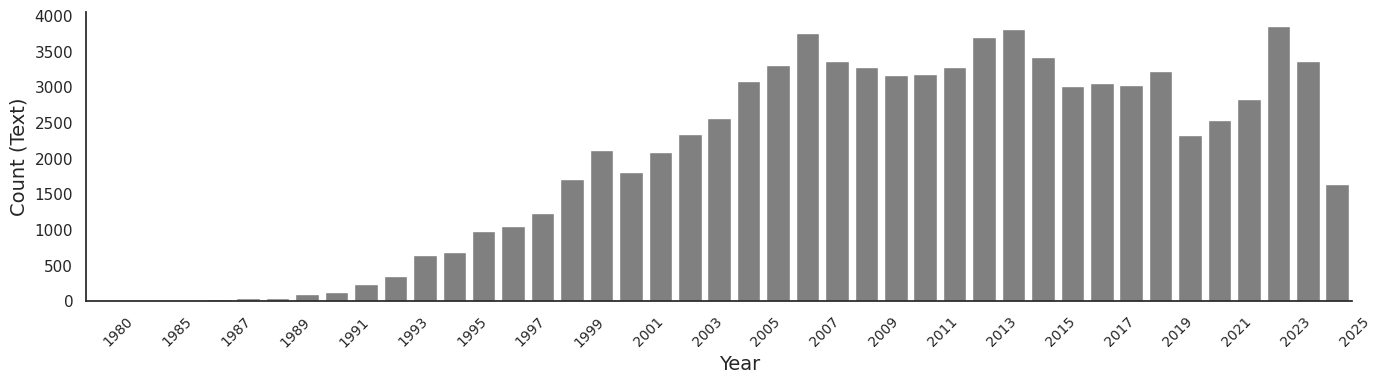

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Load CSV
text_counts_df = pd.read_csv(output_path)

# Keep year as str for Seaborn barplot
text_counts_df['year_str'] = text_counts_df['year'].astype(str)
text_counts_df['count'] = text_counts_df['count'].astype(int)

# Get range for ticks using numeric version
year_min = text_counts_df['year'].min()
year_max = text_counts_df['year'].max()

# Set classic Seaborn theme
sns.set_theme(style="white")

# Plot
plt.figure(figsize=(14, 4))
sns.barplot(data=text_counts_df, x='year_str', y='count', color='grey')

plt.xlabel('Year', fontsize=14, ha='left')
plt.ylabel('Count (Text)', fontsize=14)

plt.xticks(
    ticks=range(0, len(text_counts_df), 2),  # every 2nd tick index
    labels=text_counts_df['year_str'][::2],  # corresponding year labels
    rotation=45,
    ha='left',
    fontsize=10
)

sns.despine()
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(desc_output_folder, "text_count_byyear_classic_seaborn.png"))
plt.close()

In [113]:
print("--- Dataframe ID Column Check ---")
print(f"ID Column Data Type: {df['id'].dtype}")
print(f"Number of Unique IDs: {df['id'].nunique()}")
print(f"Number of rows with NaNs in 'id': {df['id'].isna().sum()}")

# Replace the ID with the one that gave you the KeyError
trouble_id = 1507626216
print(f"Trouble ID found in df['id'].values: {trouble_id in df['id'].values}")

# This will check for the ID as an integer, float, and string
print(f"Trouble ID as int: {int(trouble_id) in df['id'].values}")
print(f"Trouble ID as float: {float(trouble_id) in df['id'].values}")
print(f"Trouble ID as string: {str(trouble_id) in df['id'].values}")
print("-----------------------------------")

--- Dataframe ID Column Check ---
ID Column Data Type: object
Number of Unique IDs: 84504
Number of rows with NaNs in 'id': 0
Trouble ID found in df['id'].values: False
Trouble ID as int: False
Trouble ID as float: False
Trouble ID as string: True
-----------------------------------


In [114]:
df

,id,title,text,date,publisher,source_type,pub_province,year
0,1357126016,A Message for the Class of 2013; Dear Graduate...,"Thank you, President and Trustees. I have to c...",2013-05-31,Dow Jones & Company Inc.,"Blogs, Podcasts, & Websites",NJ,2013
2,865291198,Questionnaire: Rick Morelli,Full Name: Rick Morelli Date of Birth: 1-21-...,2011-05-09,The Citizens' Voice,Newspapers,PA,2011
3,3031447880,How do we help our 4-year-old who always wants...,Dear Meghan: Do you have any advice for setti...,2024-04-04,WP Company LLC d/b/a The Washington Post,Newspapers,DC,2024
4,2459482004,"To Boston parents, treatment of most vulnerabl...",Sign up to receive a newsletter for The Great ...,2020-11-12,"Boston Globe Media Partners, LLC",Newspapers,MA,2020
6,3054141660,"When my son turned 20, we took a hike to refle...","When my son turned 13, we went on a hike toget...",2024-05-13,"Insider, Inc.","Blogs, Podcasts, & Websites",NY,2024
...,...,...,...,...,...,...,...,...
107185,911464985,CHILDREN IN DANGER: LEAD'S ENDURING THREAT,"Remodelers, agencies strive to remove lead fro...",2000-05-23,Gannett Media Corp,Newspapers,VA,2000
107187,1708523328,"With Science against them, CDC Promotes Fluori...","NEW YORK, Sept. 1, 2015 /PRNewswire-USNewswire...",2015-09-01,PR Newswire Association LLC,Wire Feeds,NY,2015
107188,2535994751,State of the Nation's Mental Health: Stress is...,(BPT) - Our nation reported more mental health...,2021-06-01,The Citizens' Voice,Newspapers,PA,2021
107189,2012573674,THE FRAGILE STAGE: Considering the wide range ...,March 10--Editor's Note: This is the first of ...,2018-03-10,Tribune Content Agency LLC,Wire Feeds,None,2018


In [115]:
#Normalisation functions for duplicate filtering

import os
import re
import pandas as pd
import networkx as nx
from datasketch import MinHash, MinHashLSH

# ----------------------
# Normalize + Shingle
# ----------------------
def normalize(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^\w\s]', '', text)
    return text.strip()

def get_shingles(text, k=5):
    words = normalize(text).split()
    return set([' '.join(words[i:i+k]) for i in range(len(words) - k + 1)])

def jaccard_sim(text1, text2, k=5):
    s1 = get_shingles(text1, k)
    s2 = get_shingles(text2, k)
    return len(s1 & s2) / len(s1 | s2) if (s1 | s2) else 0

# Create output folder
output_dir = "output/duplicatefiltering"
os.makedirs(output_dir, exist_ok=True)


In [116]:
#preparing data for filter

cleaned_file = f"{output_dir}/articles_cleaned.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(cleaned_file):
    df = pd.read_csv(cleaned_file)
    print(f"Loaded cleaned articles from {cleaned_file}")
else:
    df['id'] = df['id'].astype(str).str.strip()
    df_indexed = df.set_index('id')
    df.to_csv(cleaned_file, index=False)
    print(f"Saved cleaned articles to {cleaned_file}")


Loaded cleaned articles from output/duplicatefiltering/articles_cleaned.csv


In [117]:
#Build Minihashes and LSH

num_perm = 256
lsh_threshold = 0.4
shingle_size = 5
validate_threshold = 0.6

#Query and Validate potential Duplicates with exact jaccard similariy on Shingles (articles grouped by year)

validated_file = f"{output_dir}/validated_duplicates.csv"

force = True   # <<<<<< Set to True to force recomputation

if not force and os.path.exists("output/validated_duplicates.csv"):   
    df_validated_duplicates = pd.read_csv(validated_file)
    print(f"Loaded validated duplicates from {validated_file}")
else:
    duplicate_records = []
    seen = set()

    # Process each year separately
    for year, df_year in df.groupby('year'):
        print(f"Processing year {year} with {len(df_year)} articles...")
        lsh = MinHashLSH(threshold=lsh_threshold, num_perm=num_perm)
        minhashes = {}

        # Build MinHashes and insert into LSH
        for idx, text in zip(df_year['id'], df_year['text']):
            shingles = get_shingles(text, k=shingle_size)
            m = MinHash(num_perm=num_perm)
            for sh in shingles:
                m.update(sh.encode('utf8'))
            lsh.insert(idx, m)
            minhashes[idx] = m

        # Query duplicates within the same year
        for idx, mh in minhashes.items():
            if idx in seen:
                continue
            matches = lsh.query(mh)
            for m in matches:
                if m != idx:
                    text1 = df_year.loc[df_year['id']==idx, 'text'].values[0]
                    text2 = df_year.loc[df_year['id']==m, 'text'].values[0]
                    sim = jaccard_sim(text1, text2, k=shingle_size)
                    if sim >= validate_threshold:
                        duplicate_records.append({
                            "id": idx,
                            "duplicate_id": m,
                            "publisher": df_year.loc[df_year['id']==idx, 'publisher'].values[0],
                            "duplicate_publisher": df_year.loc[df_year['id']==m, 'publisher'].values[0],
                            "year": year,
                            "jaccard": sim
                        })
            seen.update(matches)

    df_validated_duplicates = pd.DataFrame(duplicate_records)
    df_validated_duplicates.to_csv(validated_file, index=False)
    print(f"Saved validated duplicates to {validated_file}")
    
    print(df_validated_duplicates.head(20))



Processing year 1980 with 1 articles...
Processing year 1983 with 2 articles...
Processing year 1985 with 7 articles...
Processing year 1986 with 5 articles...
Processing year 1987 with 34 articles...
Processing year 1988 with 43 articles...
Processing year 1989 with 50 articles...
Processing year 1990 with 99 articles...
Processing year 1991 with 134 articles...
Processing year 1992 with 237 articles...
Processing year 1993 with 355 articles...
Processing year 1994 with 651 articles...
Processing year 1995 with 696 articles...
Processing year 1996 with 990 articles...
Processing year 1997 with 1061 articles...
Processing year 1998 with 1232 articles...
Processing year 1999 with 1707 articles...
Processing year 2000 with 2113 articles...
Processing year 2001 with 1804 articles...
Processing year 2002 with 2091 articles...
Processing year 2003 with 2344 articles...
Processing year 2004 with 2569 articles...
Processing year 2005 with 3082 articles...
Processing year 2006 with 3305 articl

In [118]:
#Build Clusters for comparison

# Create output folder
output_dir = "output/duplicatefiltering"
os.makedirs(output_dir, exist_ok=True)
clusters_file = f"{output_dir}/articles_with_clusters.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(clusters_file):
    df_with_clusters = pd.read_csv(clusters_file)
    clusters = df_with_clusters['cluster_id'].dropna().unique().tolist()
    print(f"Loaded articles with clusters from {clusters_file}")
else:
    if not df_validated_duplicates.empty:
        G = nx.Graph()
        G.add_edges_from(df_validated_duplicates[['id', 'duplicate_id']].itertuples(index=False, name=None))
        clusters = [list(c) for c in nx.connected_components(G)]
        cluster_map = {node: i for i, comp in enumerate(clusters) for node in comp}
        df_with_clusters = df.copy()
        df_with_clusters['cluster_id'] = df_with_clusters['id'].map(cluster_map)
    else:
        clusters = []
        df_with_clusters = df.copy()
        df_with_clusters['cluster_id'] = None

    df_with_clusters.to_csv(clusters_file, index=False)
    print(f"Saved articles with clusters to {clusters_file}")
    
    print(df_with_clusters.head(20))


Loaded articles with clusters from output/duplicatefiltering/articles_with_clusters.csv


In [119]:
#Deduplicate at cluster level (keeping longest article)

dedup_file = f"{output_dir}/deduplicated_articles.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(dedup_file):
    df_noduplicates = pd.read_csv(dedup_file)
    print(f"Loaded deduplicated articles from {dedup_file}")
else:
    if clusters:
        df_with_clusters['text_len'] = df_with_clusters['text'].fillna("").str.split().str.len()
        representatives = (
            df_with_clusters.dropna(subset=['cluster_id'])
            .sort_values('text_len', ascending=False)
            .groupby('cluster_id')
            .first()
            .reset_index()
        )
        df_noduplicates = pd.concat([
            representatives,
            df_with_clusters[df_with_clusters['cluster_id'].isna()]
        ])
    else:
        df_noduplicates = df.copy()

    df_noduplicates.to_csv(dedup_file, index=False)
    print(f"Saved deduplicated articles to {dedup_file}")
    
    print(df_noduplicates.head(10))


Loaded deduplicated articles from output/duplicatefiltering/deduplicated_articles.csv


In [120]:
#Prepare sample for inspection

sample_file = f"{output_dir}/sample_duplicates.csv"

force = True   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(sample_file):
    sample_dupes = pd.read_csv(sample_file)
    print(f"Loaded sample duplicates from {sample_file}")
else:
    if not df_validated_duplicates.empty:
        sample_dupes = df_validated_duplicates.merge(
            df[['id', 'text']], left_on='id', right_on='id'
        ).rename(columns={'text': 'text_orig'})
        sample_dupes = sample_dupes.merge(
            df[['id', 'text']], left_on='duplicate_id', right_on='id'
        ).rename(columns={'text': 'text_dup'})
    else:
        sample_dupes = pd.DataFrame()

    sample_dupes.to_csv(sample_file, index=False)
    print(f"Saved sample duplicates to {sample_file}")

print("Found duplicate clusters:", len(clusters))
print("Articles after deduplication:", len(df_noduplicates))
print("Sample duplicates shape:", sample_dupes.shape)

print(sample_dupes.head(20))


Saved sample duplicates to output/duplicatefiltering/sample_duplicates.csv
Found duplicate clusters: 11460
Articles after deduplication: 63963
Sample duplicates shape: (17800, 9)
          id_x  duplicate_id                                    publisher  \
0    389443159     389500519              Tribune Publishing Company, LLC   
1    276989239     292482107              Tribune Publishing Company, LLC   
2    280637107     280631090         Los Angeles Times Communications LLC   
3    280637107     280691101         Los Angeles Times Communications LLC   
4    280637107     280737551         Los Angeles Times Communications LLC   
5    267974988     267983121                     Freedom Newspapers, Inc.   
6    280948519     280810442         Los Angeles Times Communications LLC   
7    262654649    1834303976                     Times Publishing Company   
8    283104008     277858616              Tribune Publishing Company, LLC   
9    379147254     281206290                       

In [141]:
#Check what other articles belong to an article's cluster

# Pick an article ID you care about
article_id = 2825640137   # <-- replace with your actual article ID

# Find its cluster
cluster_id = df_with_clusters.loc[df_with_clusters['id'] == article_id, 'cluster_id'].values

if len(cluster_id) == 0:
    print(f"Article {article_id} not found in df_with_clusters")
else:
    cluster_id = cluster_id[0]
    if cluster_id == -1:
        print(f"Article {article_id} is unique (not in any duplicate cluster)")
    else:
        # Get all articles in that cluster
        cluster_members = df_with_clusters[df_with_clusters['cluster_id'] == cluster_id]

        print(f"Cluster {cluster_id} contains {len(cluster_members)} articles:")
        print(cluster_members[['id', 'publisher', 'year']])


Cluster 10290.0 contains 3 articles:
               id                        publisher  year
230    2825640137  Tribune Publishing Company, LLC  2023
21439  2825550743       Tribune Content Agency LLC  2023
33728  2826114461  Tribune Publishing Company, LLC  2023


In [142]:
# ----------------------
# Inspect text from all articles in a single cluster
# ----------------------

# How many articles per cluster (optional summary)
# cluster_sizes = df_with_clusters.groupby('cluster_id')['id'].count().sort_values(ascending=False)
# print("Top cluster sizes:\n", cluster_sizes.head(20))  # Show largest clusters

# Pick a cluster_id you want to inspect
cluster_to_check = 10290  # <-- change this to the cluster you want

# Get all articles in that cluster
cluster_articles = df_with_clusters[df_with_clusters['cluster_id'] == cluster_to_check].copy()

# Add preview and length columns
cluster_articles['text'] = cluster_articles['text'].fillna('')
cluster_articles['text_preview'] = cluster_articles['text'].str[:1000]
cluster_articles['length'] = cluster_articles['text'].str.split().str.len()

# Summary
print(f"Cluster {cluster_to_check} contains {len(cluster_articles)} articles\n")

# Display main details
cols_to_show = ['id', 'year', 'publisher', 'length', 'text_preview']
print(cluster_articles[cols_to_show].to_string(index=False))  # Full display, no index


Cluster 10290 contains 3 articles

        id  year                       publisher  length                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [123]:
#Random sample of clusters

import numpy as np

# Pick 3 random clusters to inspect
random_clusters = np.random.choice(df_with_clusters['cluster_id'].dropna().unique(), 10, replace=False)

for cid in random_clusters:
    print(f"\n=== Cluster {cid} ===")
    cluster_articles = df_with_clusters[df_with_clusters['cluster_id'] == cid][['id', 'publisher', 'year', 'text']]
    for idx, row in cluster_articles.iterrows():
        print(f"\nID: {row['id']}, Publisher: {row['publisher']}, Year: {row['year']}")
        print(f"Text (first 200 chars): {row['text'][:400]}...")



=== Cluster 4276.0 ===

ID: 2593783264, Publisher: Gannett Media Corp, Year: 2011
Text (first 200 chars): Illinois Peterson ex-wife tells of threats JOLIET — The second wife of a former suburban Chicago police sergeant testified at a pretrial hearing Tuesday that he had threatened to kill her and said he could make it look like an accident. Victoria Connolly said her ex-husband, Drew Peterson, pulled a gun on her three or four times when they were married, once putting it to her head and telling her h...

ID: 2610086280, Publisher: Gannett Media Corp, Year: 2011
Text (first 200 chars): Illinois Peterson ex-wife tells of threats JOLIET — The second wife of a former suburban Chicago police sergeant testified at a pretrial hearing Tuesday that he had threatened to kill her and said he could make it look like an accident. Victoria Connolly said her ex-husband, Drew Peterson, pulled a gun on her three or four times when they were married, once putting it to her head and telling her h...

I

In [124]:
# ----------------------------
# Borderline cases with metadata: title, publisher, and text preview
# ----------------------------

# Filter borderline similarities
lower_bound = 0.60
upper_bound = 0.65

borderline_cases = df_validated_duplicates[
    (df_validated_duplicates['jaccard'] >= lower_bound) &
    (df_validated_duplicates['jaccard'] < upper_bound)
].copy()

# --- Merge metadata for article A ---
df_a = df[['id', 'title', 'publisher', 'text']].rename(columns={
    'id': 'id_a', 'title': 'title_a', 'publisher': 'publisher_a', 'text': 'text_a'
})
borderline_cases = borderline_cases.merge(df_a, left_on='id', right_on='id_a', how='left')

# --- Merge metadata for article B ---
df_b = df[['id', 'title', 'publisher', 'text']].rename(columns={
    'id': 'id_b', 'title': 'title_b', 'publisher': 'publisher_b', 'text': 'text_b'
})
borderline_cases = borderline_cases.merge(df_b, left_on='duplicate_id', right_on='id_b', how='left')

# --- Add text previews ---
preview_len = 300
borderline_cases['preview_a'] = borderline_cases['text_a'].str.slice(0, preview_len)
borderline_cases['preview_b'] = borderline_cases['text_b'].str.slice(0, preview_len)

# --- Publisher match flag ---
borderline_cases['publisher_match'] = borderline_cases['publisher_a'] == borderline_cases['publisher_b']

# --- Title similarity function ---
def jaccard_title_sim(t1, t2):
    set1, set2 = set(str(t1).lower().split()), set(str(t2).lower().split())
    return len(set1 & set2) / len(set1 | set2) if set1 | set2 else 0

borderline_cases['title_sim'] = borderline_cases.apply(
    lambda row: jaccard_title_sim(row['title_a'], row['title_b']),
    axis=1
)

# --- Save to CSV ---
borderline_file = f"{output_dir}/borderline_cases_{lower_bound}_to_{upper_bound}_with_titles.csv"
borderline_cases.to_csv(borderline_file, index=False)
print(f"\n✅ Saved borderline cases with metadata to: {borderline_file}")

# --- Show preview ---
cols = [
    'id', 'duplicate_id', 'jaccard',
    'title_sim', 'publisher_match',
    'title_a', 'title_b', 'preview_a', 'preview_b'
]
display(borderline_cases[cols].sample(min(5, len(borderline_cases))))




✅ Saved borderline cases with metadata to: output/duplicatefiltering/borderline_cases_0.6_to_0.65_with_titles.csv


,id,duplicate_id,jaccard,title_sim,publisher_match,title_a,title_b,preview_a,preview_b
959,2697656438,2697654053,0.633188,0.533333,True,Journal of the American Medical Association-Ps...,JAMA Psychiatry Journal Issues Research Articl...,The Journal of the American Medical Associatio...,"JAMA Psychiatry, an international peer-reviewe..."
407,368730329,405172982,0.608696,0.181818,False,Officials wary of teens' abuse of ADHD drugs,Spike in ADHD drug abuse reported,CHICAGO - Calls to poison-control centers abou...,CHICAGO - Calls to poison control centers abo...
43,288896198,403860033,0.608567,0.333333,False,Take a Moment Thursday to Wish John Glenn Gods...,LET'S WISH JOHN GLENN GODSPEED AS HE MAKES HIS...,Dear Ann: My good friend and fellow astronaut ...,To find out more about Ann Landers and read he...
645,1625014581,1623803434,0.605263,0.777778,False,Mallinckrodt's stock falls 6.5 percent on FDA ...,Mallinckrodt's stock falls 5 percent on FDA move,Shares of Mallinckrodt PLC fell 6.5 percent Th...,Nov. 13--Updated at 12:50 p.m. Shares of Malli...
599,1266485124,1266484977,0.636531,0.352941,True,14-year-old charged in Jenks homicide was on p...,14-year-old charged in Jenks murder was on pro...,Jan. 05-- A 14-year-old who is charged with mu...,Jan. 05-- A 14-year-old who is charged with mu...


In [125]:
#Review borderline similarity cases (simple version ignoring metadata)

# Filter borderline matches (sim between 0.6 and 0.8)
borderline_cases = df_validated_duplicates[
    (df_validated_duplicates['jaccard'] >= 0.6) &
    (df_validated_duplicates['jaccard'] < 0.65)
]

# Optional: Save for review
borderline_file = f"{output_dir}/borderline_cases.csv"
borderline_cases.to_csv(borderline_file, index=False)
print(f"Saved borderline cases to: {borderline_file}")

# Optional: Preview 5 random ones
sample_borderline = borderline_cases.sample(min(50, len(borderline_cases)))
print("\nSample borderline matches (0.4 <= Jaccard < 0.45):")
display(sample_borderline)


Saved borderline cases to: output/duplicatefiltering/borderline_cases.csv

Sample borderline matches (0.4 <= Jaccard < 0.45):


,id,duplicate_id,publisher,duplicate_publisher,year,jaccard
14990,2825640137,2826114461,"Tribune Publishing Company, LLC","Tribune Publishing Company, LLC",2023,0.625592
2278,379827978,379742577,"New England Newspapers, Inc.","New England Newspapers, Inc.",2006,0.645441
3763,444739275,444683828,Business Wire,Business Wire,2008,0.613900
13527,2426877426,2421823437,"Tribune Publishing Company, LLC",New York Times Company,2020,0.601237
2843,439781013,439784409,Gannett Media Corp,Gannett Media Corp,2007,0.627586
3319,352207271,284058884,Bay Area News Group,"Tribune Publishing Company, LLC",2007,0.639175
4648,448187516,468491126,PR Newswire Association LLC,Targeted News Service,2009,0.643872
2185,420433382,420486117,"Tribune Publishing Company, LLC","Tribune Publishing Company, LLC",2006,0.627368
16256,2774195364,2774363347,"USA Today, a division of Gannett Satellite Inf...","USA Today, a division of Gannett Satellite Inf...",2023,0.646274
4971,756852657,756108160,Halifax Media Group,Halifax Media Group,2010,0.622472


In [126]:
df_noduplicates

,cluster_id,id,title,text,date,publisher,source_type,pub_province,year,text_len
0,0.0,306897379,Improving the Lot of the Learning Disabled,A couple with a learning-disabled son came to ...,1987-02-03,WP Company LLC d/b/a The Washington Post,Newspapers,DC,1987,1249
1,1.0,389443159,"SCHOOL SWITCHES CAMPUS, NOT APPROACH",SCHOOLS WEST BROWARD When he was enrolled a...,1987-11-17,"Tribune Publishing Company, LLC",Newspapers,IL,1987,842
2,2.0,292639858,Troiani Case Co-Defendant Pleads Guilty to Murder,In a plea bargain that saved him from possible...,1987-11-05,Los Angeles Times Communications LLC,Newspapers,CA,1987,1196
3,3.0,292482107,Paying Close Attention to Hyperactive Adults N...,A man walks down the street He says why a...,1987-04-14,Los Angeles Times Communications LLC,Newspapers,CA,1987,995
4,4.0,280637107,Foster Parents Learn About Infant Addicts,"Merry Lloyd looked down at Rusty, the tiny fos...",1988-12-11,Los Angeles Times Communications LLC,Newspapers,CA,1988,1654
...,...,...,...,...,...,...,...,...,...,...
63958,NaN,3046829497,CT not on track to meet 2030 climate goals as ...,Apr. 26 - Greenhouse gas emissions in Connecti...,2024-04-26,Tribune Content Agency LLC,Wire Feeds,NaN,2024,596
63959,NaN,444289192,Mental Health Professionals Gather in San Fran...,"Industry: HEALTH CARE/HOSPITALS IRVINE, Calif....",1998-10-08,PR Newswire Association LLC,Wire Feeds,NY,1998,413
63960,NaN,911464985,CHILDREN IN DANGER: LEAD'S ENDURING THREAT,"Remodelers, agencies strive to remove lead fro...",2000-05-23,Gannett Media Corp,Newspapers,VA,2000,2802
63961,NaN,1708523328,"With Science against them, CDC Promotes Fluori...","NEW YORK, Sept. 1, 2015 /PRNewswire-USNewswire...",2015-09-01,PR Newswire Association LLC,Wire Feeds,NY,2015,662


In [136]:

# ----------------------
# Compare Jaccard similarity between two articles
# ----------------------

# Pick your two article IDs
id1 = 276200286   # <-- replace with first article ID
id2 = 435442250          # <-- replace with second article ID

# Get the texts
try:
    text1 = df.loc[df['id'] == id1, 'text'].values[0]
    text2 = df.loc[df['id'] == id2, 'text'].values[0]
except IndexError:
    raise ValueError("One or both article IDs not found in df")

# Compute shingles
shingle_size = 5
shingles1 = get_shingles(text1, k=shingle_size)
shingles2 = get_shingles(text2, k=shingle_size)

# Jaccard similarity
intersection = len(shingles1 & shingles2)
union = len(shingles1 | shingles2)
jaccard = intersection / union if union > 0 else 0

print(f"Jaccard similarity between {id1} and {id2}: {jaccard:.3f}")

Jaccard similarity between 276200286 and 435442250: 0.264


--- Similarity Distribution Analysis ---
Total unique similar pairs found: 4775
Average Jaccard Similarity: 0.9285
Median Jaccard Similarity: 1.0000
Minimum Jaccard Similarity: 0.2344
Maximum Jaccard Similarity: 1.0000


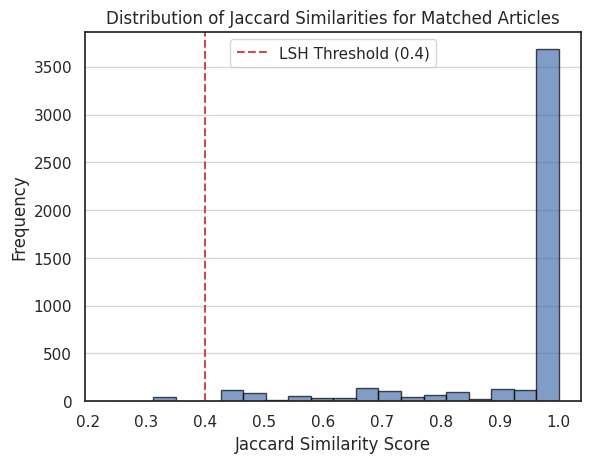

In [128]:
# ----------------------------------------------------
# 6. Analyze the Distribution of Similarities
# ----------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# A list to store all similarity scores found
all_similarities = []
# A set to track pairs we have already compared
seen_pairs = set()

# Iterate through each article's MinHash
for idx, mh in minhashes.items():
    # Use LSH to find candidate duplicates for this article
    candidate_matches = lsh.query(mh)
    
    for m in candidate_matches:
        # **FIX:** We now keep the matched ID as a string for consistency
        # There is no need for `m = int(m)` here.
        
        # Avoid self-comparison and double-counting pairs
        if m == idx:
            continue
        # Sort the pair to ensure (1, 2) and (2, 1) are treated as the same
        # This will now work correctly since both `idx` and `m` are strings.
        pair = tuple(sorted((idx, m)))
        if pair in seen_pairs:
            continue
        
        # Get the MinHash signature of the matched article
        m_match = minhashes[m]
        
        # Calculate the Jaccard similarity and store it
        jaccard_sim = mh.jaccard(m_match)
        all_similarities.append(jaccard_sim)
        
        # Add the pair to our seen set
        seen_pairs.add(pair)

print("--- Similarity Distribution Analysis ---")
print(f"Total unique similar pairs found: {len(all_similarities)}")
if all_similarities:
    print(f"Average Jaccard Similarity: {np.mean(all_similarities):.4f}")
    print(f"Median Jaccard Similarity: {np.median(all_similarities):.4f}")
    print(f"Minimum Jaccard Similarity: {min(all_similarities):.4f}")
    print(f"Maximum Jaccard Similarity: {max(all_similarities):.4f}")

    # Plot a histogram of the similarities
    plt.hist(all_similarities, bins=20, edgecolor='black', alpha=0.7)
    plt.title('Distribution of Jaccard Similarities for Matched Articles')
    plt.xlabel('Jaccard Similarity Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.axvline(x=lsh_threshold, color='r', linestyle='--', label=f'LSH Threshold ({lsh_threshold})')
    plt.legend()
    plt.show()

Sampling 1000 articles for analysis...
Starting all-pairs Jaccard calculation on the sample...
Finished. Calculated 499500 similarity scores.
--- Sample Similarity Distribution Analysis ---
Average Jaccard Similarity: 0.0001
Median Jaccard Similarity: 0.0000
Minimum Jaccard Similarity: 0.0000
Maximum Jaccard Similarity: 1.0000


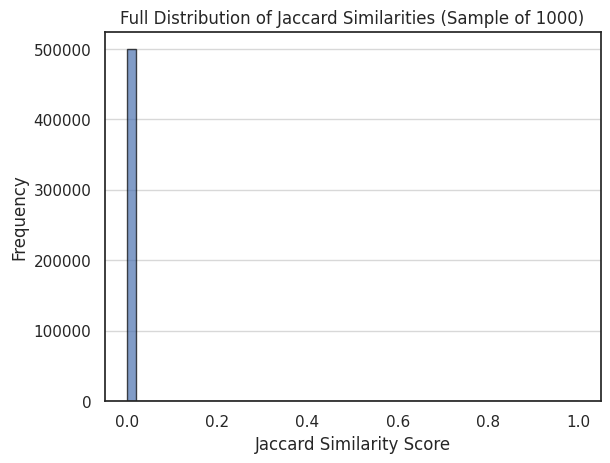

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

# ----------------------------------------------------------------------
# 2. Sample the DataFrame and Calculate All-Pairs Similarities
# ----------------------------------------------------------------------

# Set the sample size
sample_size = 1000

# Randomly sample the DataFrame to get a representative subset
# .copy() prevents the SettingWithCopyWarning
df_sample = df.sample(n=min(sample_size, len(df))).copy()
print(f"Sampling {len(df_sample)} articles for analysis...")

# Calculate shingles for each article in the sample and store them in a dictionary
# Assumes get_shingles() is already defined
shingles_dict = {}
for idx, text in zip(df_sample['id'], df_sample['text']):
    shingles_dict[idx] = get_shingles(text)

# List to store all similarity scores
all_similarities = []

# Perform the all-pairs comparison on the sample
# itertools.combinations is a very efficient way to get every unique pair
all_pairs = itertools.combinations(shingles_dict.keys(), 2)

print("Starting all-pairs Jaccard calculation on the sample...")
for id1, id2 in all_pairs:
    shingles1 = shingles_dict[id1]
    shingles2 = shingles_dict[id2]
    
    # Calculate the Jaccard similarity: |A intersect B| / |A union B|
    try:
        jaccard_sim = len(shingles1.intersection(shingles2)) / len(shingles1.union(shingles2))
        all_similarities.append(jaccard_sim)
    except ZeroDivisionError:
        # This handles cases where two articles have no words (e.g., empty text)
        all_similarities.append(0.0)

print(f"Finished. Calculated {len(all_similarities)} similarity scores.")

# ----------------------------------------------------------------------
# 3. Analyze and Plot the Distribution
# ----------------------------------------------------------------------
if all_similarities:
    print("--- Sample Similarity Distribution Analysis ---")
    print(f"Average Jaccard Similarity: {np.mean(all_similarities):.4f}")
    print(f"Median Jaccard Similarity: {np.median(all_similarities):.4f}")
    print(f"Minimum Jaccard Similarity: {min(all_similarities):.4f}")
    print(f"Maximum Jaccard Similarity: {max(all_similarities):.4f}")

    # Plot a histogram of the similarities
    plt.hist(all_similarities, bins=50, edgecolor='black', alpha=0.7)
    plt.title(f'Full Distribution of Jaccard Similarities (Sample of {len(df_sample)})')
    plt.xlabel('Jaccard Similarity Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

In [130]:
#Checking for duplicates

# Filter for publisher "Ganett Media Corp" and year 2018
filtered_articles = df_noduplicates[
    (df_noduplicates['publisher'] == "Gannett Media Corp") &
   (df_noduplicates['year'] == 2018) &
   (df_noduplicates['title'] == "'Serious concerns'")
]

# Print the results
print(filtered_articles)

      cluster_id          id               title  \
8258      8258.0  2109142103  'Serious concerns'   

                                                   text        date  \
8258  Local and state health officials expressed ser...  2018-09-20   

               publisher source_type pub_province  year  text_len  
8258  Gannett Media Corp  Newspapers           VA  2018      1490  


In [143]:
#df_noduplicates = df_noduplicates.drop(columns=['cluster_id', 'text_len'])
df_noduplicates

,id,title,text,date,publisher,source_type,pub_province,year
0,306897379,Improving the Lot of the Learning Disabled,A couple with a learning-disabled son came to ...,1987-02-03,WP Company LLC d/b/a The Washington Post,Newspapers,DC,1987
1,389443159,"SCHOOL SWITCHES CAMPUS, NOT APPROACH",SCHOOLS WEST BROWARD When he was enrolled a...,1987-11-17,"Tribune Publishing Company, LLC",Newspapers,IL,1987
2,292639858,Troiani Case Co-Defendant Pleads Guilty to Murder,In a plea bargain that saved him from possible...,1987-11-05,Los Angeles Times Communications LLC,Newspapers,CA,1987
3,292482107,Paying Close Attention to Hyperactive Adults N...,A man walks down the street He says why a...,1987-04-14,Los Angeles Times Communications LLC,Newspapers,CA,1987
4,280637107,Foster Parents Learn About Infant Addicts,"Merry Lloyd looked down at Rusty, the tiny fos...",1988-12-11,Los Angeles Times Communications LLC,Newspapers,CA,1988
...,...,...,...,...,...,...,...,...
63958,3046829497,CT not on track to meet 2030 climate goals as ...,Apr. 26 - Greenhouse gas emissions in Connecti...,2024-04-26,Tribune Content Agency LLC,Wire Feeds,NaN,2024
63959,444289192,Mental Health Professionals Gather in San Fran...,"Industry: HEALTH CARE/HOSPITALS IRVINE, Calif....",1998-10-08,PR Newswire Association LLC,Wire Feeds,NY,1998
63960,911464985,CHILDREN IN DANGER: LEAD'S ENDURING THREAT,"Remodelers, agencies strive to remove lead fro...",2000-05-23,Gannett Media Corp,Newspapers,VA,2000
63961,1708523328,"With Science against them, CDC Promotes Fluori...","NEW YORK, Sept. 1, 2015 /PRNewswire-USNewswire...",2015-09-01,PR Newswire Association LLC,Wire Feeds,NY,2015


In [135]:
#Cosine sim of random sample of articles from deduplicated data

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# --- 1. Sample 1000 articles after deduplication ---
sampled_df = df_noduplicates.sample(n=1000, random_state=42).reset_index(drop=True)

# --- 2. TF-IDF Vectorization of full text ---
vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
tfidf_matrix = vectorizer.fit_transform(sampled_df['text'])

# --- 3. Compute Cosine Similarity ---
cosine_sim = cosine_similarity(tfidf_matrix)

# --- 4. Get top N most similar pairs ---
import numpy as np

N = 50  # top N pairs to keep
similar_pairs = []

for i in range(len(sampled_df)):
    for j in range(i+1, len(sampled_df)):  # only upper triangle
        score = cosine_sim[i, j]
        similar_pairs.append((i, j, score))

# Sort by similarity score descending
similar_pairs.sort(key=lambda x: x[2], reverse=True)
top_pairs = similar_pairs[:N]

# --- 5. Build output DataFrame with metadata ---
records = []
for i, j, sim in top_pairs:
    row = {
        'id_a': sampled_df.loc[i, 'id'],
        'id_b': sampled_df.loc[j, 'id'],
        'cosine_sim': round(sim, 4),
        'title_a': sampled_df.loc[i, 'title'],
        'title_b': sampled_df.loc[j, 'title'],
        'publisher_a': sampled_df.loc[i, 'publisher'],
        'publisher_b': sampled_df.loc[j, 'publisher'],
        'year': sampled_df.loc[i, 'year'],  # assumed same
        'text_preview_a': sampled_df.loc[i, 'text'][:300],
        'text_preview_b': sampled_df.loc[j, 'text'][:300],
    }
    records.append(row)

df_top_similar = pd.DataFrame(records)

# --- 6. Display or save results ---
from IPython.display import display
display(df_top_similar)

# Optional: save to CSV
df_top_similar.to_csv("output/top_similar_article_pairs.csv", index=False)
print("Saved top similar article pairs to output/top_similar_article_pairs.csv")


,id_a,id_b,cosine_sim,title_a,title_b,publisher_a,publisher_b,year,text_preview_a,text_preview_b
0,435442250,276200286,0.9298,Community calendar,Community calendar,Halifax Media Group,Halifax Media Group,2010,The registration deadline is today for the Ter...,"United Blood Services, 2000 Audubon Ave., Suit..."
1,368712708,368938032,0.8637,community calendar,What's Happening,Telegraph Herald,Telegraph Herald,2009,adult events tuesday Women's Midday Escape...,Today -- Sundown Family Week-end. Sundown Mo...
2,2457128977,2457401533,0.8595,"Round Rock school board: Xiao, Bone, Harrison,...","Xiao, Bone, Harrison, Weston win seats on Roun...",Tribune Content Agency LLC,Tribune Content Agency LLC,2020,Early results from Travis and Williamson count...,Final Election Day returns from Travis and Wil...
3,331371773,331373650,0.8073,Obituaries: ; Obit,Obituaries: ; Obit,Charleston Newspapers,Charleston Newspapers,2005,"Eva Amerson Eva Amerson, 97, of Charleston ...",Anthony Michael Adams Anthony Michael Adams...
4,451749279,453368590,0.7649,Shire Acquires FOSRENOL Patent Rights,Expiry of Hart-Scott-Rodino Waiting Period for...,PR Newswire Association LLC,PR Newswire Association LLC,2004,"BASINGSTOKE, England, March 23 /PRNewswire-Fir...","BASINGSTOKE, England and PHILADELPHIA, August ..."
5,1021819299,356937305,0.7638,Shire Announces that the US Food and Drug Admi...,INTUNIV(TM) - Shire Files Suit Against Anchen ...,PR Newswire Association LLC,PR Newswire Association LLC,2012,"PHILADELPHIA, June 23, 2012 /PRNewswire/ -- ...","DUBLIN and PHILADELPHIA, June 3, 2010 /PRNewsw..."
6,1021819299,453368590,0.7361,Shire Announces that the US Food and Drug Admi...,Expiry of Hart-Scott-Rodino Waiting Period for...,PR Newswire Association LLC,PR Newswire Association LLC,2012,"PHILADELPHIA, June 23, 2012 /PRNewswire/ -- ...","BASINGSTOKE, England and PHILADELPHIA, August ..."
7,2176687101,2199264251,0.7248,Wheeler's EPA Keeps Brain-Damaging Chlorpyrifo...,"Sen. Udall, Senate Leaders Introduce Bill to B...",Targeted News Service,Targeted News Service,2019,Earthjustice issued the following news release...,The Pesticide Action Network North America iss...
8,451749279,451489753,0.7117,Shire Acquires FOSRENOL Patent Rights,Product Development Update Session - May 10th,PR Newswire Association LLC,PR Newswire Association LLC,2004,"BASINGSTOKE, England, March 23 /PRNewswire-Fir...","BASINGSTOKE, England and PHILADELPHIA, April 1..."
9,453911647,451489753,0.6937,Third Quarter 2006 Results Date Notification -...,Product Development Update Session - May 10th,PR Newswire Association LLC,PR Newswire Association LLC,2006,"BASINGSTOKE, England and PHILADELPHIA, Pennsyl...","BASINGSTOKE, England and PHILADELPHIA, April 1..."


Saved top similar article pairs to output/top_similar_article_pairs.csv


## Save Dataframe as CSV

Make sure to change the `output_file` variable (defined at the top of script) to desired output file name before running this cell.

In [138]:
# Save output to file
df_noduplicates.to_csv(output_file)

In [139]:
# Modify output_file to desired save name
df_noduplicates.to_csv("../input/ADHD_US_newsstream.tsv", sep="\t", index=False)

In [140]:
# Sample 1000 rows and save to a new TSV
sample_df = df_noduplicates.sample(n=1000, random_state=42)  # random_state ensures reproducibility
sample_df.to_csv("../input/ADHD_US_newsstream_SAMPLE_1000.tsv", sep="\t", index=False)